# Prediksi Modern & Machine Learning
**Prediksi default pembayaran kartu kredit bulan berikutnya** (Default of Credit Card Clients Dataset, UCI/Kaggle)

Nama: Alverrell Gustivierda Zidna Fann

NIM: 2404220021

Alur: Data Understanding → Data Preparation → Experiment 1 (baseline) → 2 (preprocessing) → 3 (perbandingan model) → 4 (tuning) → 5 (advanced model).
Metrik utama **F1-score** (kelas 1 = default); metrik pendukung Accuracy, Precision, Recall. Semua CV memakai **5-fold Stratified CV** pada training set.

In [6]:
#!pip install -q kagglehub

instal kagglehub (hapus "#" pada sel diatas)

In [7]:
import os, json, warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import kagglehub

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Memuat dataset
Dataset dibaca dari `data/UCI_Credit_Card.csv` (raw dataset Kaggle, tanpa modifikasi). Jika dijalankan di Google Colab tanpa folder `data/`, sel di bawah meminta file diunggah.

In [8]:
path = kagglehub.dataset_download("uciml/default-of-credit-card-clients-dataset")
print("Folder dataset:", path)

df = pd.read_csv(os.path.join(path, "UCI_Credit_Card.csv"))
print("Dimensi:", df.shape)
df.head()

100%|██████████| 0.98M/0.98M [00:00<00:00, 80.0MB/s]

Extracting files...
Folder dataset: /root/.cache/kagglehub/datasets/uciml/default-of-credit-card-clients-dataset/versions/1
Dimensi: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


# Experiment 0. Data Understanding & Preparation

### 0.1 Dimensi, struktur, dan tipe data

In [9]:
print("Dimensi dataset:", df.shape)
df.info()

Dimensi dataset: (30000, 25)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BI

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


### 0.2 Variabel target
Target: `default.payment.next.month` (0 = tidak default, 1 = default). `ID` hanya pengenal dan tidak dipakai sebagai predictor.

                            jumlah  persen
default.payment.next.month                
0                            23364   77.88
1                             6636   22.12


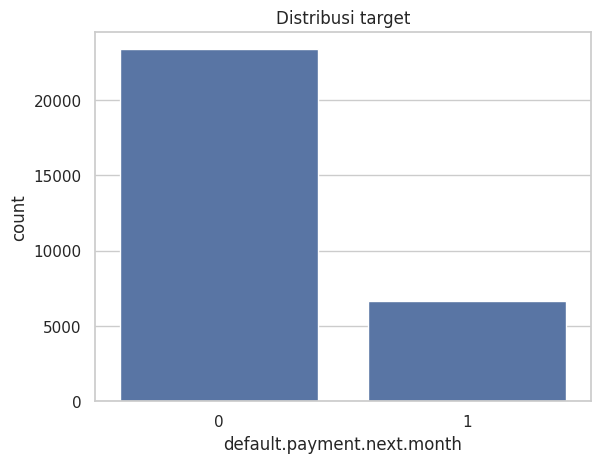

In [11]:
TARGET = "default.payment.next.month"
vc = df[TARGET].value_counts().sort_index()
print(pd.DataFrame({"jumlah": vc, "persen": (vc / len(df) * 100).round(2)}))
ax = sns.countplot(x=TARGET, data=df); ax.set_title("Distribusi target"); plt.show()

### 0.3 Missing value dan duplicate

In [13]:
print("Total missing value :", int(df.isna().sum().sum()))
print("Duplikat baris penuh :", int(df.duplicated().sum()))
print("ID unik              :", df['ID'].is_unique)
print("Duplikat (tanpa ID)  :", int(df.drop(columns='ID').duplicated().sum()))

Total missing value : 0
Duplikat baris penuh : 0
ID unik              : True
Duplikat (tanpa ID)  : 35


Tidak ada missing value. Duplikat baris (tanpa ID) ada, tetapi ini nasabah berbeda (ID unik) yang kebetulan punya profil identik. Data finansial berbentuk kategorikal/diskrit mudah berulang, jadi baris-baris ini **tidak dihapus** (ID berbeda = observasi berbeda, dan jumlah observasi 30.000 mengikuti ketentuan tugas).

### 0.4 Nilai tidak sesuai / tidak wajar

In [14]:
for c in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(c, df[c].value_counts().sort_index().to_dict())
print()
pay_cols = ["PAY_0","PAY_2","PAY_3","PAY_4","PAY_5","PAY_6"]
print("PAY_x nilai unik:", sorted(set(df[pay_cols].values.ravel())))
print("Usia: min", df.AGE.min(), "max", df.AGE.max())
print("LIMIT_BAL <= 0:", int((df.LIMIT_BAL <= 0).sum()))
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
print("BILL_AMT negatif (kelebihan bayar):", int((df[bill_cols] < 0).any(axis=1).sum()), "baris")

SEX {1: 11888, 2: 18112}
EDUCATION {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE {0: 54, 1: 13659, 2: 15964, 3: 323}

PAY_x nilai unik: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
Usia: min 21 max 79
LIMIT_BAL <= 0: 0
BILL_AMT negatif (kelebihan bayar): 1930 baris


Temuan (berdasarkan dokumentasi dataset):
- `EDUCATION` seharusnya 1–4 (1 pascasarjana, 2 universitas, 3 SMA, 4 lainnya), namun ada nilai **0, 5, 6** yang tidak terdokumentasi → digabung ke kategori 4 (*lainnya*).
- `MARRIAGE` seharusnya 1–3 (1 menikah, 2 lajang, 3 lainnya), namun ada nilai **0** → digabung ke kategori 3.
- `PAY_x` memiliki nilai −2, −1, 0, … 8. Nilai −2/−1/0 tidak terdokumentasi lengkap tetapi bermakna (tanpa pemakaian / lunas / revolving), sehingga **dipertahankan** sebagai fitur ordinal numerik.
- `BILL_AMT` negatif adalah kelebihan pembayaran yang wajar, jadi dipertahankan.
- Kolom `PAY_0` sebenarnya status bulan September (PAY_1); namanya dibiarkan sesuai raw dataset.

### 0.5 Eksplorasi singkat

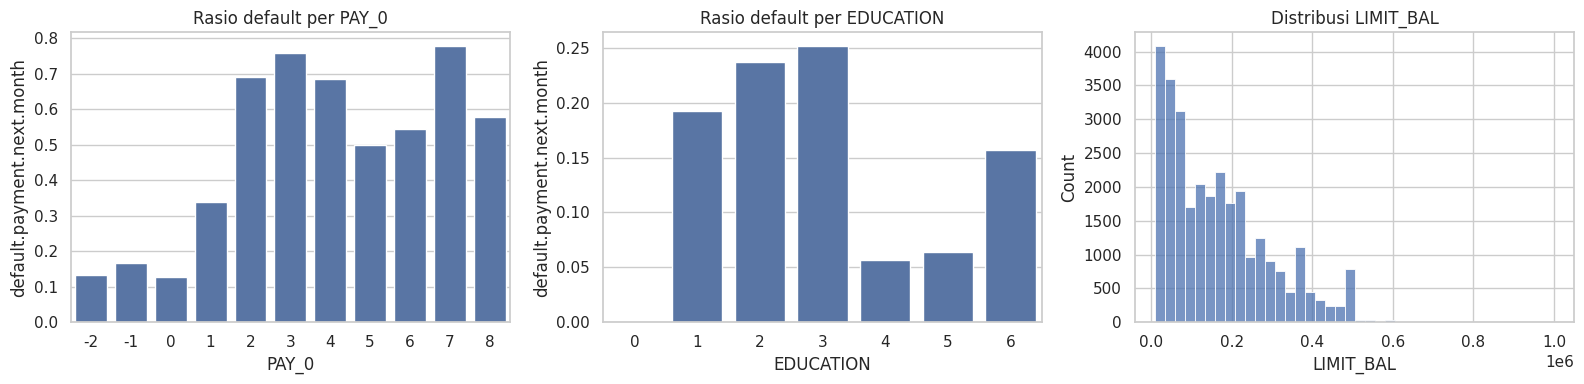

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.barplot(x="PAY_0", y=TARGET, data=df, ax=ax[0], errorbar=None); ax[0].set_title("Rasio default per PAY_0")
sns.barplot(x="EDUCATION", y=TARGET, data=df, ax=ax[1], errorbar=None); ax[1].set_title("Rasio default per EDUCATION")
sns.histplot(df.LIMIT_BAL, bins=40, ax=ax[2]); ax[2].set_title("Distribusi LIMIT_BAL")
plt.tight_layout(); plt.show()

### 0.6 Predictor, target, dan train-test split
`ID` dikeluarkan dari predictor. Split **80:20 stratified** (rasio default terjaga) dilakukan **sebelum** preprocessing dan training apa pun, sehingga tidak ada data leakage. Semua transformasi yang dipelajari dari data (scaler, encoder) dimasukkan ke dalam `Pipeline` agar hanya di-*fit* pada training fold.

In [16]:
X = df.drop(columns=["ID", TARGET])
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Rasio default train:", round(y_train.mean(), 4), "| test:", round(y_test.mean(), 4))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train: (24000, 23) | Test: (6000, 23)
Rasio default train: 0.2212 | test: 0.2212


### 0.7 Rancangan preprocessing (dipakai mulai Experiment 2)
1. **Pembersihan kategori** (aturan tetap, tidak belajar dari data): EDUCATION {0,5,6}→4, MARRIAGE {0}→3.
2. **One-hot encoding** untuk `SEX`, `EDUCATION`, `MARRIAGE` (nominal; angka kode tidak punya urutan).
3. **StandardScaler** untuk fitur numerik (LIMIT_BAL, AGE, PAY_x, BILL_AMT, PAY_AMT) — penting untuk Logistic Regression berbasis gradien/regularisasi.
Model berbasis pohon tidak butuh scaling, tetapi pipeline yang sama dipakai agar prosedur evaluasi seragam.

In [17]:
def clean_categories(d):
    d = d.copy()
    d["EDUCATION"] = d["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
    d["MARRIAGE"] = d["MARRIAGE"].replace({0: 3})
    return d

cat_cols = ["SEX", "EDUCATION", "MARRIAGE"]
num_cols = [c for c in X.columns if c not in cat_cols]

def make_preprocessor(scale=True):
    return ColumnTransformer([
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
        ("num", StandardScaler() if scale else "passthrough", num_cols),
    ])

def prep_pipeline(model, scale=True):
    return Pipeline([("clean", FunctionTransformer(clean_categories)),
                     ("prep", make_preprocessor(scale)),
                     ("model", model)])

results = {}   # menyimpan hasil semua eksperimen

def evaluate(name, estimator, store=True, fitted=False):
    t0 = time.time()
    cv_f1 = cross_val_score(estimator, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
    if not fitted:
        estimator.fit(X_train, y_train)
    pred = estimator.predict(X_test)
    r = dict(model=name,
             cv_f1=cv_f1.mean(), cv_f1_std=cv_f1.std(),
             test_accuracy=accuracy_score(y_test, pred),
             test_precision=precision_score(y_test, pred),
             test_recall=recall_score(y_test, pred),
             test_f1=f1_score(y_test, pred))
    if store: results[name] = r
    print(f"{name:35s} CV F1={r['cv_f1']:.4f} (±{r['cv_f1_std']:.4f}) | Acc={r['test_accuracy']:.4f} "
          f"Prec={r['test_precision']:.4f} Rec={r['test_recall']:.4f} F1={r['test_f1']:.4f}  [{time.time()-t0:.1f}s]")
    return r

# Experiment 1. Baseline Model
Logistic Regression pada **raw features** (hanya `ID` dibuang) tanpa scaling maupun encoding apa pun. `max_iter` dinaikkan agar solver konvergen.

In [18]:
baseline = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
r1 = evaluate("Exp1 Baseline (LogReg raw)", baseline)

Exp1 Baseline (LogReg raw)          CV F1=0.3692 (±0.0135) | Acc=0.8082 Prec=0.6841 Rec=0.2464 F1=0.3623  [114.4s]


CV F1 per fold: [0.3801 0.3774 0.381  0.3608 0.3466]


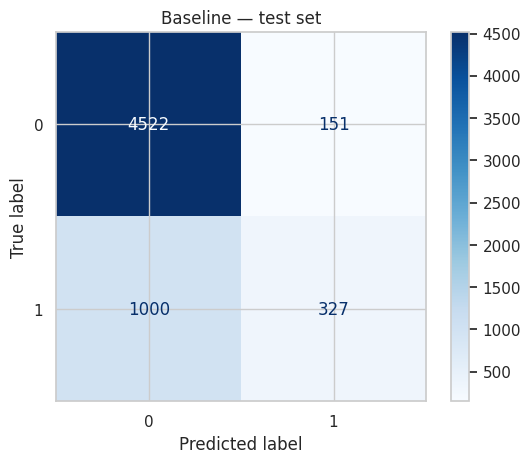

In [19]:
print("CV F1 per fold:", np.round(cross_val_score(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE), X_train, y_train, cv=cv, scoring='f1'), 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, baseline.predict(X_test))).plot(cmap="Blues"); plt.title("Baseline — test set"); plt.show()

Baseline memiliki accuracy tinggi namun recall/F1 sangat rendah: dengan target tidak seimbang (~22% default), model cenderung memprediksi hampir semua nasabah sebagai *tidak default*. Inilah alasan F1 dipakai sebagai metrik utama, bukan accuracy.

# Experiment 2. Preprocessing
Logistic Regression yang sama, tetapi dengan pembersihan kategori + one-hot encoding + standard scaling (di dalam Pipeline).

In [20]:
lr_prep = prep_pipeline(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
r2 = evaluate("Exp2 LogReg + Preprocessing", lr_prep)

Exp2 LogReg + Preprocessing         CV F1=0.3641 (±0.0151) | Acc=0.8088 Prec=0.6923 Rec=0.2442 F1=0.3610  [1.2s]


In [21]:
cmp = pd.DataFrame([r1, r2]).set_index("model")[["cv_f1","test_accuracy","test_precision","test_recall","test_f1"]]
cmp.loc["Selisih (Exp2 − Exp1)"] = cmp.iloc[1] - cmp.iloc[0]
display(cmp.round(4))
d = r2["test_f1"] - r1["test_f1"]
print(f"Perubahan Test F1: {d:+.4f} | Perubahan CV F1: {r2['cv_f1']-r1['cv_f1']:+.4f}")
print("Kesimpulan:", "preprocessing MENINGKATKAN performa." if d > 0 and r2['cv_f1'] > r1['cv_f1'] else "preprocessing TIDAK memberikan peningkatan yang konsisten.")

,cv_f1,test_accuracy,test_precision,test_recall,test_f1
model,,,,,
Exp1 Baseline (LogReg raw),0.3692,0.8082,0.6841,0.2464,0.3623
Exp2 LogReg + Preprocessing,0.3641,0.8088,0.6923,0.2442,0.3610
Selisih (Exp2 − Exp1),-0.0051,0.0007,0.0082,-0.0023,-0.0013


Perubahan Test F1: -0.0013 | Perubahan CV F1: -0.0051
Kesimpulan: preprocessing TIDAK memberikan peningkatan yang konsisten.


# Experiment 3. Model Comparison
Logistic Regression, Decision Tree, dan Random Forest dengan pipeline preprocessing yang sama (kecuali model) dan prosedur evaluasi identik. Hyperparameter masih default (Decision Tree dan Random Forest tanpa batas kedalaman). Model terbaik dipilih berdasarkan **CV F1** (bukan test set, agar test tetap menjadi data yang belum dipakai untuk memilih).

In [22]:
models3 = {
    "Exp3 Logistic Regression": LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    "Exp3 Decision Tree":       DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Exp3 Random Forest":       RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
}
pipes3 = {}
for n, m in models3.items():
    pipes3[n] = prep_pipeline(m)
    evaluate(n, pipes3[n])

Exp3 Logistic Regression            CV F1=0.3641 (±0.0151) | Acc=0.8088 Prec=0.6923 Rec=0.2442 F1=0.3610  [1.1s]
Exp3 Decision Tree                  CV F1=0.3957 (±0.0147) | Acc=0.7210 Prec=0.3749 Rec=0.3919 F1=0.3832  [4.6s]
Exp3 Random Forest                  CV F1=0.4704 (±0.0041) | Acc=0.8138 Prec=0.6371 Rec=0.3677 F1=0.4663  [60.0s]


In [23]:
t3 = pd.DataFrame([results[n] for n in models3]).set_index("model")[["cv_f1","test_accuracy","test_precision","test_recall","test_f1"]]
display(t3.round(4))
best3 = t3["cv_f1"].idxmax()
print("Model terbaik Exp 3 (berdasarkan CV F1):", best3)
best3_key = best3
results["Exp3 Best"] = dict(results[best3_key], model="Exp3 Best: " + best3_key.replace("Exp3 ", ""))

,cv_f1,test_accuracy,test_precision,test_recall,test_f1
model,,,,,
Exp3 Logistic Regression,0.3641,0.8088,0.6923,0.2442,0.3610
Exp3 Decision Tree,0.3957,0.7210,0.3749,0.3919,0.3832
Exp3 Random Forest,0.4704,0.8138,0.6371,0.3677,0.4663


Model terbaik Exp 3 (berdasarkan CV F1): Exp3 Random Forest


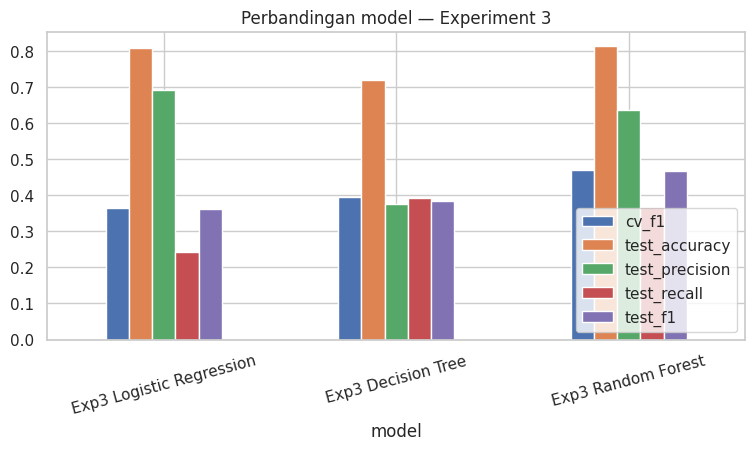

In [24]:
ax = t3.plot(kind="bar", figsize=(9, 4)); ax.set_title("Perbandingan model — Experiment 3"); plt.xticks(rotation=15); plt.legend(loc="lower right"); plt.show()

# Experiment 4. Hyperparameter Tuning
`GridSearchCV` (5-fold, scoring `f1`) pada model terbaik Exp 3. Grid disiapkan untuk ketiga jenis model, dan hanya grid milik pemenang Exp 3 yang dijalankan.

In [25]:
grids = {
    "Exp3 Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"],
        "model__penalty": ["l1", "l2"],
        "model__solver": ["liblinear"],
    },
    "Exp3 Decision Tree": {
        "model__max_depth": [3, 5, 7, 10, None],
        "model__min_samples_leaf": [1, 10, 50],
        "model__criterion": ["gini", "entropy"],
        "model__class_weight": [None, "balanced"],
    },
    "Exp3 Random Forest": {
        "model__n_estimators": [200, 400],
        "model__max_depth": [8, 12, None],
        "model__min_samples_leaf": [1, 5],
        "model__class_weight": [None, "balanced"],
    },
}
grid = grids[best3_key]
print("Model:", best3_key); print("Hyperparameter yang diuji:"); [print(" ", k, "→", v) for k, v in grid.items()]
n_comb = int(np.prod([len(v) for v in grid.values()])); print("Jumlah kombinasi:", n_comb, "× 5 fold =", n_comb * 5, "fit")

Model: Exp3 Random Forest
Hyperparameter yang diuji:
  model__n_estimators → [200, 400]
  model__max_depth → [8, 12, None]
  model__min_samples_leaf → [1, 5]
  model__class_weight → [None, 'balanced']
Jumlah kombinasi: 24 × 5 fold = 120 fit


In [27]:
t0 = time.time()
gs = GridSearchCV(prep_pipeline(clone(pipes3[best3_key].named_steps["model"])),
                  grid, scoring="f1", cv=cv, n_jobs=-1, refit=True)
gs.fit(X_train, y_train)
print(f"Selesai dalam {time.time()-t0:.0f} detik")
print("Kombinasi terbaik :", gs.best_params_)
print("Best CV F1        :", round(gs.best_score_, 4))

Selesai dalam 2267 detik
Kombinasi terbaik : {'model__class_weight': 'balanced', 'model__max_depth': 12, 'model__min_samples_leaf': 5, 'model__n_estimators': 400}
Best CV F1        : 0.5452


In [28]:
pred4 = gs.predict(X_test)
r4 = dict(model="Exp4 Tuned: " + best3_key.replace("Exp3 ", ""),
          cv_f1=gs.best_score_, cv_f1_std=gs.cv_results_["std_test_score"][gs.best_index_],
          test_accuracy=accuracy_score(y_test, pred4), test_precision=precision_score(y_test, pred4),
          test_recall=recall_score(y_test, pred4), test_f1=f1_score(y_test, pred4))
results["Exp4 Tuned"] = r4
results["Exp4 Tuned"]["best_params"] = {k: (v if v is None or isinstance(v, (int, float, str)) else str(v)) for k, v in gs.best_params_.items()}
cols = ["cv_f1","test_accuracy","test_precision","test_recall","test_f1"]
before_after = pd.DataFrame([results["Exp3 Best"], r4]).set_index("model")[cols]
before_after.loc["Selisih (sesudah − sebelum)"] = before_after.iloc[1] - before_after.iloc[0]
display(before_after.round(4))
top = pd.DataFrame(gs.cv_results_).sort_values("rank_test_score").head(5)[["params","mean_test_score","std_test_score"]]
display(top.round(4))
d4 = r4["test_f1"] - results["Exp3 Best"]["test_f1"]
print("Kesimpulan:", "tuning MENINGKATKAN performa." if d4 > 0 else "tuning TIDAK meningkatkan performa.", f"(Δ Test F1 = {d4:+.4f}, Δ CV F1 = {r4['cv_f1']-results['Exp3 Best']['cv_f1']:+.4f})")

,cv_f1,test_accuracy,test_precision,test_recall,test_f1
model,,,,,
Exp3 Best: Random Forest,0.4704,0.8138,0.6371,0.3677,0.4663
Exp4 Tuned: Random Forest,0.5452,0.7927,0.5295,0.5607,0.5447
Selisih (sesudah − sebelum),0.0748,-0.0212,-0.1075,0.1929,0.0783


,params,mean_test_score,std_test_score
19,"{'model__class_weight': 'balanced', 'model__ma...",0.5452,0.0042
18,"{'model__class_weight': 'balanced', 'model__ma...",0.5446,0.0031
14,"{'model__class_weight': 'balanced', 'model__ma...",0.5436,0.0057
12,"{'model__class_weight': 'balanced', 'model__ma...",0.5430,0.0058
13,"{'model__class_weight': 'balanced', 'model__ma...",0.5429,0.0059


Kesimpulan: tuning MENINGKATKAN performa. (Δ Test F1 = +0.0783, Δ CV F1 = +0.0748)


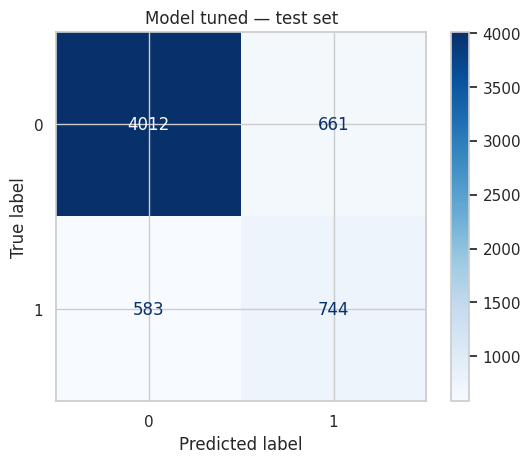

In [29]:
ConfusionMatrixDisplay(confusion_matrix(y_test, pred4)).plot(cmap="Blues"); plt.title("Model tuned — test set"); plt.show()

# Experiment 5. Advanced Model
Dua metode boosting dibandingkan: **Gradient Boosting** (scikit-learn) dan **XGBoost**, dengan pipeline dan prosedur evaluasi yang sama. Hyperparameter memakai konfigurasi moderat (tanpa tuning ekstensif) agar adil terhadap aturan tugas; pemenang dipilih lewat CV F1.

In [30]:
adv = {
    "Exp5 Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE),
    "Exp5 XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                                  eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=2),
}
adv_pipes = {}
for n, m in adv.items():
    adv_pipes[n] = prep_pipeline(m)
    evaluate(n, adv_pipes[n])

Exp5 Gradient Boosting              CV F1=0.4782 (±0.0077) | Acc=0.8190 Prec=0.6667 Rec=0.3632 F1=0.4702  [153.5s]
Exp5 XGBoost                        CV F1=0.4783 (±0.0085) | Acc=0.8178 Prec=0.6630 Rec=0.3587 F1=0.4655  [6.5s]


In [31]:
t5 = pd.DataFrame([results[n] for n in adv]).set_index("model")[cols]
display(t5.round(4))
best5 = t5["cv_f1"].idxmax()
results["Exp5 Best"] = dict(results[best5], model="Exp5 Advanced: " + best5.replace("Exp5 ", ""))
print("Model advanced terpilih (CV F1):", best5)

cmp5 = pd.DataFrame([results["Exp4 Tuned"], results["Exp5 Best"]]).set_index("model")[cols]
cmp5.loc["Selisih (Exp5 − Exp4)"] = cmp5.iloc[1] - cmp5.iloc[0]
display(cmp5.round(4))
d5 = results["Exp5 Best"]["test_f1"] - results["Exp4 Tuned"]["test_f1"]
print("Kesimpulan:", "model advanced LEBIH BAIK." if d5 > 0 else "model advanced TIDAK lebih baik.", f"(Δ Test F1 = {d5:+.4f}, Δ CV F1 = {results['Exp5 Best']['cv_f1']-results['Exp4 Tuned']['cv_f1']:+.4f})")

,cv_f1,test_accuracy,test_precision,test_recall,test_f1
model,,,,,
Exp5 Gradient Boosting,0.4782,0.8190,0.6667,0.3632,0.4702
Exp5 XGBoost,0.4783,0.8178,0.6630,0.3587,0.4655


Model advanced terpilih (CV F1): Exp5 XGBoost


,cv_f1,test_accuracy,test_precision,test_recall,test_f1
model,,,,,
Exp4 Tuned: Random Forest,0.5452,0.7927,0.5295,0.5607,0.5447
Exp5 Advanced: XGBoost,0.4783,0.8178,0.6630,0.3587,0.4655
Selisih (Exp5 − Exp4),-0.0669,0.0252,0.1334,-0.2020,-0.0791


Kesimpulan: model advanced TIDAK lebih baik. (Δ Test F1 = -0.0791, Δ CV F1 = -0.0669)


# Ringkasan Seluruh Eksperimen

In [32]:
order = ["Exp1 Baseline (LogReg raw)", "Exp2 LogReg + Preprocessing", "Exp3 Best", "Exp4 Tuned", "Exp5 Best"]
labels = ["1 - Baseline", "2 - Baseline + Preprocessing", "3. Model Comparison ", "4. Tuned Model", "5. Advanced Model"]
summary = pd.DataFrame([results[k] for k in order])
summary.insert(0, "Experiment", labels)
summary = summary[["Experiment","model","cv_f1","test_accuracy","test_precision","test_recall","test_f1"]]
summary.columns = ["Experiment","Model","CV F1","Test Accuracy","Test Precision","Test Recall","Test F1"]
display(summary.round(4))

best_final = summary.loc[summary["CV F1"].idxmax(), "Model"]
print("CV F1 tertinggi:", best_final)
print("Test F1 tertinggi:", summary.loc[summary["Test F1"].idxmax(), "Model"])

out_dir = "../reports" if path.startswith("../") else "reports"
os.makedirs(out_dir, exist_ok=True)
summary.to_csv(f"{out_dir}/summary_results.csv", index=False)
all_res = {k: v for k, v in results.items()}
all_res["_meta"] = {"n_train": len(X_train), "n_test": len(X_test), "default_rate": float(y.mean()),
                    "exp3_table": {n: results[n] for n in models3}, "exp5_table": {n: results[n] for n in adv},
                    "best3": best3_key, "best5": best5, "tuning_grid": {k: [str(x) for x in v] for k, v in grid.items()}}
with open(f"{out_dir}/results.json", "w") as f:
    json.dump(all_res, f, indent=2, default=float)

,Experiment,Model,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,1 - Baseline,Exp1 Baseline (LogReg raw),0.3692,0.8082,0.6841,0.2464,0.3623
1,2 - Baseline + Preprocessing,Exp2 LogReg + Preprocessing,0.3641,0.8088,0.6923,0.2442,0.3610
2,3. Model Comparison,Exp3 Best: Random Forest,0.4704,0.8138,0.6371,0.3677,0.4663
3,4. Tuned Model,Exp4 Tuned: Random Forest,0.5452,0.7927,0.5295,0.5607,0.5447
4,5. Advanced Model,Exp5 Advanced: XGBoost,0.4783,0.8178,0.6630,0.3587,0.4655


CV F1 tertinggi: Exp4 Tuned: Random Forest
Test F1 tertinggi: Exp4 Tuned: Random Forest


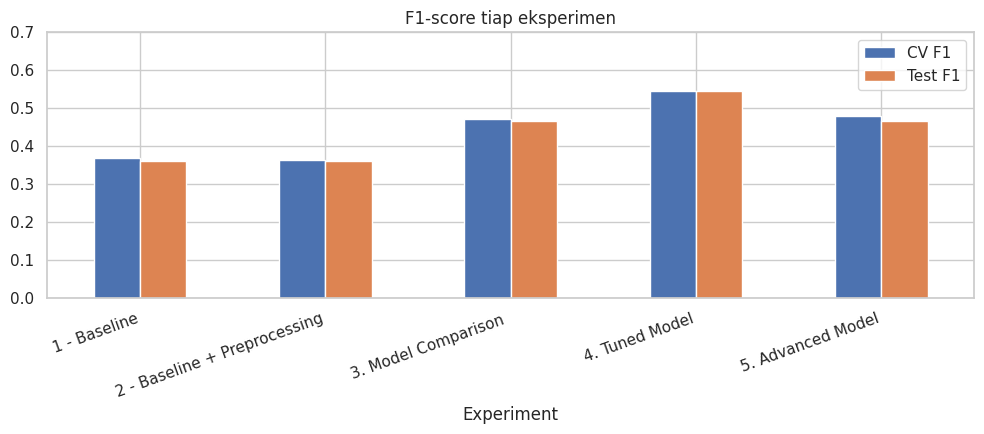

In [33]:
ax = summary.set_index("Experiment")[["CV F1","Test F1"]].plot(kind="bar", figsize=(10, 4.5))
ax.set_ylim(0, max(0.7, summary[["CV F1","Test F1"]].values.max() + 0.05)); ax.set_title("F1-score tiap eksperimen"); plt.xticks(rotation=20, ha="right")
plt.tight_layout(); plt.savefig(f"{out_dir}/f1_per_experiment.png", dpi=150); plt.show()